# Graph Mining II: groups and missing links
## Finding study groups, and suggesting new study partners
**Salem Othman · Student notebook · Self-study class, Friday, November 6**

**There is no class meeting today.** Work through this notebook on your own, in order. Everything you need is explained here, and the slides `GM2_Slides.pptx` draw each algorithm step by step. Read the slide named in each part before you start that part.

**Submit** this notebook with all outputs in Brightspace by **Friday, November 6, 11:59 PM**. It counts as today's in-class exercise. **Your project proposal is also due today at 11:59 PM.** Plan your time.

---

On Wednesday you measured **single students**: who has the most links, who is a bridge, whose advice matters. Today you look at the **structure** of the whole network, with the same 60 students:

1. **Communities:** which students form groups that are linked mostly to each other? Is that just their major, or something else?
2. **Link prediction:** which pairs of students are not linked, but look as if they should be? This is how "people you may know" works, and it leads into recommender systems in two weeks.

The data is the same **practice data as Wednesday, generated by code** for this exercise: the students and the help log are not real.

### Today's five steps
| Part | Step | What you do | Slides | Exercise |
|---|---|---|---|---|
| 1 | Communities | Let an algorithm find the groups, and compare them with majors | 3–8 | E1 |
| 2 | Modularity | Score how good a grouping is | 9–13 | E2 |
| 3 | Suggestions | Suggest new study partners for one student | 14–18 | E3 |
| 4 | Evaluate | Hide real links and see if the method finds them again | 19–21 | E4 |
| 5 | Audit | Check an AI's summary against your numbers | 22 | E5 |

**How to work:** same as Wednesday. Write the code yourself under each numbered step, keep the variable names, and run the Check cells.
- **Setup problem?** If the first code cell says `ModuleNotFoundError: No module named 'networkx'` (or pandas, numpy, matplotlib), run `%pip install networkx` (or the missing name) in a new cell, then **Kernel → Restart** and run from the top. Still failing? Open the notebook in Google Colab (File → Upload notebook): all four libraries are already installed there.
- **Stuck for more than 10 minutes?** Re-read the explanation and the hints, post your question in the Brightspace discussion, and move on. You may ask an AI tool to **explain** an error, not to write the exercise.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
RANDOM_STATE = 42

GROUP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cc2", "#5f6b73"]


def draw_groups(graph, group_of, highlight=(), title=""):
    """Draw the network with each node coloured by its group number (group_of: {name: group})."""
    pos = nx.spring_layout(graph, seed=7)
    fig, ax = plt.subplots(figsize=(9, 7))
    nx.draw_networkx_edges(graph, pos, ax=ax, alpha=0.25, width=0.8)
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_size=90, edgecolors="white",
                           node_color=[GROUP_COLORS[group_of[n] % 6] for n in graph.nodes])
    nx.draw_networkx_labels(graph, pos, ax=ax, labels={n: n for n in highlight}, font_size=11, font_weight="bold")
    ax.set_title(title)
    ax.axis("off")
    plt.show()


def check(label, passed):
    """Print PASS or FIX for one requirement."""
    print(("PASS  " if passed else "FIX   ") + label)

def ready(value, step):
    """True when the exercise above is done. Otherwise print a reminder and return False.

    It never raises, so a blank exercise cell can never stop the class with a red
    traceback: the Check cell just tells the student what to do next.
    """
    if value is None:
        print(f"{step} is not finished yet.")
        print("Write your code in the exercise cell above, run that cell, then run this one again.")
        return False
    return True

print("networkx version:", nx.__version__)
print("Setup complete.")

networkx version: 3.7
Setup complete.


# Part 0 · The same students, the same help log
This is Wednesday's data. The cell also rebuilds the two graphs from Wednesday, so you can start here even if you didn't finish GM1:
- `G`: directed, asker → helper
- `U`: undirected, "at least one of these two asked the other for help" (one ask is enough; it doesn't mean they meet often)

Today everything uses `U`.

In [2]:
rng = np.random.default_rng(1104)

# 60 students who use the library's study rooms. When one student asks another for help with
# coursework (in person or on the course chat), the library's study-help survey records it.
names = ["Ava", "Liam", "Noah", "Emma", "Mia", "Ethan", "Zoe", "Lucas", "Aria", "Mason",
         "Leo", "Nora", "Omar", "Ivy", "Ryan", "Lily", "Sam", "Grace", "Jack", "Chloe",
         "Owen", "Ruby", "Adam", "Hana", "Eli", "Maya", "Finn", "Sara", "Theo", "Lena",
         "Kai", "Iris", "Ben", "Yara", "Max", "Elle", "Dev", "Rosa", "Jay", "Nina",
         "Alex", "Tara", "Luca", "Amir", "Jade", "Cole", "Rhea", "Ian", "Mila", "Hugo",
         "Ana", "Reza", "Tess", "Gabe", "Lina", "Wes", "June", "Pablo", "Dina", "Rami"]
majors = ["Computer Science"] * 18 + ["Data Science"] * 15 + ["Mechanical Eng"] * 15 + ["Architecture"] * 12
students = pd.DataFrame({"name": names, "major": majors})

def asks(group, p):
    """Every ordered pair (a asks b) inside a group happens with probability p."""
    return [(a, b) for a in group for b in group if a != b and rng.random() < p]

by_major = students.groupby("major")["name"].apply(list)
edges = []
for major, people in by_major.items():
    edges += asks([p for p in people if p != "Ana"], 0.16)

# A robotics team: 3 Computer Science and 3 Mechanical Eng students who work together every week.
robotics = ["Lucas", "Aria", "Leo", "Jay", "Nina", "Cole"]
edges += asks(robotics, 0.7)
# Omar (Computer Science) tutors: lots of students from three majors ask him for help.
for person in rng.choice(by_major["Computer Science"] + by_major["Data Science"] + by_major["Mechanical Eng"], 16, replace=False):
    if person != "Omar":
        edges.append((person, "Omar"))
# When Omar is stuck himself, he asks Nora.
edges += [("Omar", "Nora")]
# Architecture mostly keeps to itself. Ana is the only Architecture student who also
# works with two Mechanical Eng students.
edges += [("Ana", "Mila"), ("Hugo", "Ana"), ("Ana", "June"), ("Ana", "Max"), ("Elle", "Ana")]
# Every student asked or helped at least one classmate.
linked = {p for e in edges for p in e}
for person, major in zip(names, majors):
    if person not in linked:
        edges.append((person, rng.choice([p for p in by_major[major] if p != person and p != "Ana"])))

# Friends of friends: two students who both work with the same two or more classmates
# often end up asking each other too.
pairs = {frozenset(e) for e in edges}
neighbours = {p: set() for p in names}
for a, b in edges:
    neighbours[a].add(b); neighbours[b].add(a)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        if frozenset((a, b)) not in pairs and not {"Ana", "Omar", "Nora"} & {a, b} and len(neighbours[a] & neighbours[b]) >= 2 and rng.random() < 0.35:
            edges.append((a, b))

help_log = (pd.DataFrame(edges, columns=["asker", "helper"]).drop_duplicates()
              .assign(times=lambda d: rng.integers(1, 9, len(d)))
              .sample(frac=1, random_state=1).reset_index(drop=True))

# Wednesday's graphs, rebuilt.
G = nx.from_pandas_edgelist(help_log, source="asker", target="helper", create_using=nx.DiGraph)
G.add_nodes_from(students["name"])
U = G.to_undirected()
major_of = dict(zip(students["name"], students["major"]))

print("students:", U.number_of_nodes(), "| links:", U.number_of_edges())

students: 60 | links: 180


# Part 1 · Communities  *(slides 3–8)*
A **community** is a group of nodes with **many links inside the group and few links to the rest**. In a social network it's a circle of friends; in a web graph, a set of pages on one topic; in a bank's transfer network, possibly a fraud ring.

It is **clustering for graphs**. k-means grouped rows that were *close in distance*; community detection groups nodes that are *densely linked*. As with k-means, nobody tells the algorithm the answer.

We use the **Louvain method** (slides 5–7):
1. Start with every node in its own community.
2. Move each node into the neighbouring community that raises the **modularity** score most (Part 2 explains the score).
3. When no move helps, merge each community into a single "super-node" and repeat on the smaller graph.
4. Stop when nothing raises the score.

```python
groups = nx.community.louvain_communities(U, seed=RANDOM_STATE)   # a list of sets of names
```

The algorithm has a random element (the order in which it visits nodes), so we fix `seed`, as with `random_state`. With a different networkx version your groups may differ slightly; that's fine.

### E1 · Find the communities
**Predict:** will the communities simply be the four majors?

In [3]:
groups = None
group_of = None
group_table = None

# Write your code below. Your code must create the variables set to None above.

# 1. groups: the Louvain communities of U, with seed=RANDOM_STATE.
#    Print how many groups there are and the size of each.
groups = nx.community.louvain_communities(U, seed=RANDOM_STATE)
print(f"Number of groups: {len(groups)}, sizes: {[len(g) for g in groups]}")

# 2. group_of: a dictionary {name: group number}, numbering the groups 0, 1, 2, ...
#    Hint: {name: i for i, members in enumerate(groups) for name in members}
group_of = {name: i for i, members in enumerate(groups) for name in members}

# 3. group_table: a crosstab of major (rows) against group number (columns). Display it.
#    Hint: pd.crosstab(students["major"], students["name"].map(group_of))
group_table = pd.crosstab(students["major"], students["name"].map(group_of))
display(group_table)


Number of groups: 4, sizes: [16, 12, 13, 19]


name,0,1,2,3
major,,,,
Architecture,0,12,0,0
Computer Science,1,0,13,4
Data Science,15,0,0,0
Mechanical Eng,0,0,0,15


**Check E1**

In [4]:
if ready(groups, "E1") and ready(group_of, "E1") and ready(group_table, "E1"):
    check("every student is in exactly one group",
          sum(len(g) for g in groups) == len(students) and set().union(*groups) == set(students["name"]))
    check("group_of gives a group to every student", len(group_of) == len(students))
    check("group_of matches groups", all(name in groups[group_of[name]] for name in group_of))
    check("groups are the Louvain communities of U with seed=RANDOM_STATE",
          sorted(map(sorted, groups)) == sorted(map(sorted, nx.community.louvain_communities(U, seed=RANDOM_STATE))))
    check("group_table is the crosstab of major against group",
          group_table.equals(pd.crosstab(students["major"], students["name"].map(group_of))))

PASS  every student is in exactly one group
PASS  group_of gives a group to every student
PASS  group_of matches groups
PASS  groups are the Louvain communities of U with seed=RANDOM_STATE
PASS  group_table is the crosstab of major against group


### Worked example · Who crosses the major lines?

group 0: 16 students, mostly Data Science; from other majors: ['Omar']
group 1: 12 students, mostly Architecture; from other majors: []
group 2: 13 students, mostly Computer Science; from other majors: []
group 3: 19 students, mostly Mechanical Eng; from other majors: ['Aria', 'Leo', 'Liam', 'Lucas']


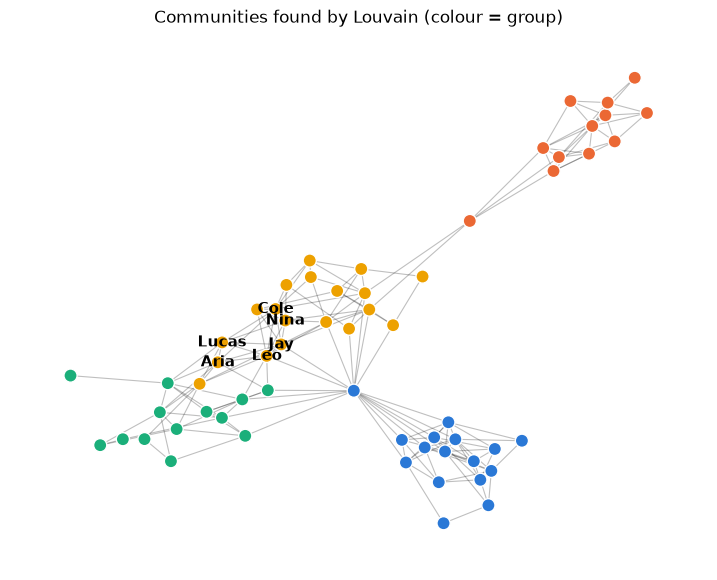

In [5]:
if ready(group_of, "E1"):
    # For each group, the most common major in it, and the students who are NOT from that major.
    for i, members in enumerate(groups):
        main = pd.Series([major_of[n] for n in members]).mode()[0]
        others = sorted(n for n in members if major_of[n] != main)
        print(f"group {i}: {len(members)} students, mostly {main}; from other majors: {others}")
    draw_groups(U, group_of, highlight=["Lucas", "Aria", "Leo", "Jay", "Nina", "Cole"],
                title="Communities found by Louvain (colour = group)")

**Write:** do the groups match the majors? Which students are in a group that is not their major's, and what do you think they have in common?

*Your answer:*


# Part 2 · Modularity: how good is a grouping?  *(slides 9–13)*
Any split of the students into groups can be scored. **Modularity** asks: *how many more links fall inside the groups than we would expect by chance?*

For each group:
1. **Actual:** the share of all links that are inside the group.
2. **Expected:** the share you'd expect inside it if links were placed at random, keeping every student's degree. That is (sum of the group's degrees ÷ (2 × number of links)), squared.
3. Add up **actual − expected** over all groups.

| Modularity | Meaning |
|---|---|
| around 0 | no better than chance (for example, everyone in one group) |
| above about 0.3 | usually clear community structure (a rough rule of thumb, not a fixed cut-off) |
| below 0 | worse than chance: the groups cut through the dense parts |

Slides 9–12 do it by hand: on two triangles joined by one link, the natural split scores **0.357** and a bad split scores **−0.214**.

```python
nx.community.modularity(U, groups)    # groups: a list of sets that covers every node
```

### E2 · Compare three groupings
**Predict:** which will score higher: the four majors, or the groups Louvain found? What will a random split score?

In [6]:
q_found = None
q_majors = None
q_random = None

# Write your code below. Your code must create the variables set to None above.

# 1. q_found: the modularity of the Louvain groups from E1.
q_found = nx.community.modularity(U, groups)

# 2. q_majors: the modularity of grouping students by major.
#    Hint: by_major = [set(names) for names in students.groupby("major")["name"]]
#          ... or students.groupby("major")["name"].apply(set).tolist()
q_majors = nx.community.modularity(
    U, students.groupby("major")["name"].apply(set).tolist()
)

# 3. q_random: the modularity of a RANDOM split into groups of the same sizes as the Louvain groups.
#    Hint: rng = np.random.default_rng(RANDOM_STATE)
#          shuffled = list(rng.permutation(students["name"]))
#          then cut shuffled into pieces of the sizes [len(g) for g in groups]
rng = np.random.default_rng(RANDOM_STATE)
shuffled = list(rng.permutation(students["name"]))
sizes = [len(g) for g in groups]
q_random = nx.community.modularity(
    U, [set(shuffled[sum(sizes[:i]) : sum(sizes[: i + 1])]) for i in range(len(sizes))]
)

# 4. Print all three, rounded to 3 decimals.
print(f"Louvain: {q_found:.3f}, Majors: {q_majors:.3f}, Random: {q_random:.3f}")


Louvain: 0.604, Majors: 0.598, Random: -0.019


**Check E2**

In [7]:
if ready(q_found, "E2") and ready(q_majors, "E2") and ready(q_random, "E2"):
    check("q_found is the modularity of the Louvain groups", np.isclose(q_found, nx.community.modularity(U, groups)))
    check("q_majors is the modularity of the four majors",
          np.isclose(q_majors, nx.community.modularity(U, students.groupby("major")["name"].apply(set).tolist())))
    check("every score is between -0.5 and 1", all(-0.5 <= q <= 1 for q in [q_found, q_majors, q_random]))
    check("the random split scores close to 0", abs(q_random) < 0.15)

PASS  q_found is the modularity of the Louvain groups
PASS  q_majors is the modularity of the four majors
PASS  every score is between -0.5 and 1
PASS  the random split scores close to 0


**Write:** rank the three groupings. What does the random split tell you, and why is Louvain's score a little higher than the majors'?

*Your answer:*

# Part 3 · Suggesting new study partners  *(slides 14–18)*
**Link prediction** asks: which pairs who are **not** linked yet are most likely to link? In social networks the best simple clue is **shared friends**: two people with many friends in common usually end up meeting.

Two scores for a pair (A, B) that is not linked:
- **Common neighbours:** how many students are linked to both A and B.
- **Jaccard:** common neighbours ÷ all distinct neighbours of A and B together. Between 0 and 1. It is fairer than a plain count, because a very popular student shares neighbours with everyone just by having so many.

```python
list(nx.common_neighbors(U, "Gabe", "Mila"))                    # the shared neighbours
list(nx.jaccard_coefficient(U, [("Gabe", "Mila"), ("Gabe", "Ana")]))   # (a, b, score) for each pair
```

Slides 14–17 work it out by hand: T and P share 2 of 3 neighbours, Jaccard 2/3.

**Careful:** a high score means two students are **likely to be linked**. It does not mean they would be **good** study partners: the network knows nothing about their courses, schedules or how well they explain things.

### E3 · Who should Gabe study with?
**Predict:** will Gabe's top suggestions be from his own major?

In [8]:
suggestions = None

student = "Gabe"

# Write your code below. Your code must create the variables set to None above.

# 1. Make the list of candidate pairs: (student, other) for every other student
#    who is NOT already linked to student.
#    Hint: [(student, other) for other in U.nodes if other != student and not U.has_edge(student, other)]
pairs = [
    (student, other)
    for other in U.nodes
    if other != student and not U.has_edge(student, other)
]

# 2. suggestions: a DataFrame with columns other, jaccard, common (number of common neighbours),
#    sorted by jaccard, largest first. Display the top 5, plus the major of each "other".
#    Hint: nx.jaccard_coefficient(U, pairs) gives (a, b, score) for each pair
#    Hint: len(list(nx.common_neighbors(U, a, b)))
suggestions = (
    pd.DataFrame(
        [
            {
                "other": o,
                "jaccard": score,
                "common": len(list(nx.common_neighbors(U, student, o))),
            }
            for _, o, score in nx.jaccard_coefficient(U, pairs)
        ]
    )
    .sort_values("jaccard", ascending=False)
    .reset_index(drop=True)
)
display(
    suggestions.merge(students.rename(columns={"name": "other"}), on="other").head(5)
)


,other,jaccard,common,major
0,Lina,0.571429,4,Architecture
1,Mila,0.444444,4,Architecture
2,Pablo,0.250000,2,Architecture
3,Hugo,0.200000,2,Architecture
4,Ana,0.100000,1,Architecture


**Check E3**

In [9]:
if ready(suggestions, "E3"):
    check("one row per student not yet linked to the student",
          len(suggestions) == len(students) - 1 - U.degree(student))
    check("nobody already linked is suggested", not any(U.has_edge(student, o) for o in suggestions["other"]))
    check("sorted by jaccard, largest first", suggestions["jaccard"].is_monotonic_decreasing)
    def _jac(o):
        a, b = set(U[student]), set(U[o])
        return len(a & b) / len(a | b) if a | b else 0.0
    check("every jaccard score is correct", all(np.isclose(j, _jac(o)) for o, j in zip(suggestions["other"], suggestions["jaccard"])))
    check("every common count is correct",
          all(c == len(set(U[student]) & set(U[o])) for o, c in zip(suggestions["other"], suggestions["common"])))

PASS  one row per student not yet linked to the student
PASS  nobody already linked is suggested
PASS  sorted by jaccard, largest first
PASS  every jaccard score is correct
PASS  every common count is correct


**Write:** who are Gabe's top suggestions and why? Would you send these suggestions to students? What could go wrong?

*Your answer:*


# Part 4 · Does it work? Hide links and try to find them  *(slides 19–21)*
How do we know the scores mean anything? Use the **train/test idea** from classification:
1. **Hide** some real links (the "test" links), keeping the rest as the training graph.
2. Score every unlinked pair in the training graph.
3. Take the top-scored pairs. How many of them are hidden real links?

**precision@20** = hidden links found among the top 20 ÷ 20.

**Baseline:** if you picked 20 pairs at random, the expected precision would be (hidden links ÷ candidate pairs), which is tiny, because almost all pairs are unlinked. Compare with that, the way you compared classifiers with the majority baseline.

**What this test does and doesn't show.** It checks whether the method can **recover links we know exist** but hid. That's a useful stand-in, but it is not a test of the **future**: we don't know which of the other top pairs will link later, and links that form next term may not look like the ones we hid. So precision@20 is an estimate, not a guarantee.

The cell below hides 20 links for you, the same 20 for everyone.

### E4 · Evaluate Jaccard link prediction
**Predict:** out of the top 20 suggestions, how many will be real hidden links?

In [10]:
candidates = None
top_pairs = None
hits = None
precision_at_20 = None
random_precision = None

# Hide 20 real links. The rest is the training graph.
rng = np.random.default_rng(RANDOM_STATE)
all_links = sorted(tuple(sorted(link)) for link in U.edges())
hidden = [all_links[i] for i in rng.choice(len(all_links), 20, replace=False)]
train_graph = U.copy()
train_graph.remove_edges_from(hidden)
print(
    "hidden links:",
    len(hidden),
    "| links left for training:",
    train_graph.number_of_edges(),
)

# Write your code below. Your code must create the variables set to None above.

# 1. candidates: every unlinked pair in train_graph.   Hint: list(nx.non_edges(train_graph))
candidates = list(nx.non_edges(train_graph))

# 2. top_pairs: the 20 candidate pairs with the highest Jaccard score in train_graph,
#    each pair written in alphabetical order (a, b) so it can be compared with hidden.
#    Hint: scores = sorted(nx.jaccard_coefficient(train_graph, candidates), key=lambda t: t[2], reverse=True)
#    Hint: tuple(sorted((a, b)))
top_pairs = [
    tuple(sorted((a, b)))
    for a, b, _ in sorted(
        nx.jaccard_coefficient(train_graph, candidates),
        key=lambda t: t[2],
        reverse=True,
    )[:20]
]
# 3. hits: how many of top_pairs are in hidden.   Hint: len(set(top_pairs) & set(hidden))
#    precision_at_20: hits / 20
hits = len(set(top_pairs) & set(hidden))
precision_at_20 = hits / 20
# 4. random_precision: len(hidden) / len(candidates). Print all three numbers.
random_precision = len(hidden) / len(candidates)
print(
    f"Hits: {hits}, Precision@20: {precision_at_20:.3f}, Random precision: {random_precision:.4f}"
)


hidden links: 20 | links left for training: 160
Hits: 3, Precision@20: 0.150, Random precision: 0.0124


**Check E4**

In [11]:
if ready(candidates, "E4") and ready(top_pairs, "E4") and ready(hits, "E4") and ready(random_precision, "E4"):
    check("candidates are exactly the unlinked pairs of train_graph",
          len(candidates) == len(students) * (len(students) - 1) // 2 - train_graph.number_of_edges())
    check("top_pairs has 20 pairs, each in alphabetical order", len(top_pairs) == 20 and all(a < b for a, b in top_pairs))
    _all = sorted((s for _, _, s in nx.jaccard_coefficient(train_graph, list(nx.non_edges(train_graph)))), reverse=True)
    _mine = sorted((s for _, _, s in nx.jaccard_coefficient(train_graph, top_pairs)), reverse=True)
    check("top_pairs are unlinked in train_graph and have the 20 highest Jaccard scores",
          not any(train_graph.has_edge(a, b) for a, b in top_pairs) and np.allclose(_mine, _all[:20]))
    check("hits counts the hidden links among top_pairs", hits == len(set(top_pairs) & set(hidden)))
    check("precision_at_20 = hits / 20", np.isclose(precision_at_20, hits / 20))
    check("random_precision = hidden / candidates", np.isclose(random_precision, len(hidden) / len(candidates)))

PASS  candidates are exactly the unlinked pairs of train_graph
PASS  top_pairs has 20 pairs, each in alphabetical order
PASS  top_pairs are unlinked in train_graph and have the 20 highest Jaccard scores
PASS  hits counts the hidden links among top_pairs
PASS  precision_at_20 = hits / 20
PASS  random_precision = hidden / candidates


**Write:** is Jaccard link prediction useful here? Compare with random guessing, and say why most top-20 pairs are "wrong" even if the method is good.

*Your answer:*


# Part 5 · The AI's analysis
The library asks an AI assistant to summarise your results. It replies:

> "Community detection found nothing new: the groups are just the four majors, so the library already knew everything. The modularity of 0.60 means 60% of all links are inside groups. And link prediction is useless: only 3 of its 20 top suggestions were right, a 15% hit rate, which is worse than a coin flip."

### E5 · Answer the AI
**Write:** find **three** problems in the AI's answer. For each one, give the evidence from your notebook.

*Your answer:*
1. Community detection found real cross-major groups rather than just finding four majors.
2. Modularity 0.60 does not mean 60% of links are inside groups. Modularity measures the excess of links
3. 15% precision is not worse than a coin flip; the baseline guessed 1.2%, so 15% is well over 12 times better than the baseline. 


### Challenge tasks (optional)
1. Repeat E4 with **common neighbours** instead of Jaccard (sort candidates by `len(list(nx.common_neighbors(train_graph, a, b)))`). Which score finds more hidden links?
2. Run Louvain with `seed` = 1, 2, 3. Do the groups change? Does the modularity?
3. Give Gabe one suggestion from **another** major: the best-scoring non-Architecture student. Who is it, and is the score above 0?

# Exit ticket
Answer without running more code.
1. What is a community in a network, and how is finding communities like clustering?
2. Modularity compares two numbers for each group. What are they?
3. How did we test link prediction without waiting for new links to appear? What did we compare it with, and what can't this test tell us?

*Your answers:*
1. A community is a group of nodes with dense internal links and sparse external links. 
    Like clustering, nodes are grouped without prior labels.

2. The actual fraction of links inside the group versus the expected fraction from random chance.

3. We hid 20 real links, scored non-edges, and checked how many hidden links appeared in the top 20. We compared the prediction with random guessing which got 1.2%. This test cannot tell us if unhidden candidate pairs will actually become study partners later.


# Submit
- Restart the kernel and run all cells. Every check should print `PASS`.
- Every *Your answer* cell is filled in.
- Submit this notebook with its outputs in Brightspace by **Friday, November 6, 11:59 PM**.
- **Also due tonight: your team's project proposal.**

**Next week:** Friday Nov 13, Graph Mining wrap-up and Exam 2 review (no class Wednesday Nov 11, Veterans Day). **Exam 2 is Wednesday November 18** and covers frequent itemsets, clustering, text mining and graph mining.